In [33]:
# Find all CSV files available in the Google Colab environment.
# Initialize an empty list to store the paths of the CSV files.
import os
csv_files = []

# Traverse the /content directory and all its subdirectories.
for root, dirs, files in os.walk("/content"):
    # Check each file to identify CSV files.
    for file in files:
        # Add the full path of each CSV file to the list.
        if file.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, file))

# Display the list of CSV files found.
print("CSV files found:")
for file in csv_files:
    print(file)

CSV files found:
/content/Developer_Action_Plan.csv
/content/online_gaming_behavior_dataset.csv
/content/Genre_Engagement_Summary.csv
/content/outputs/results/interactive_player_prediction.csv
/content/outputs/results/player_recommendations.csv
/content/outputs/results/interactive_player_recommendations.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv


In [34]:

# Import pandas for data loading and manipulation.
# Import NumPy for numerical operations.
import pandas as pd
import numpy as np

# Specify the path of the online gaming behavior dataset.
csv_path = "/content/online_gaming_behavior_dataset.csv"

# Load the CSV file into a pandas DataFrame.
df = pd.read_csv(csv_path)

# Confirm that the dataset has been loaded successfully.
print("Dataset loaded successfully!")

# Display the number of rows and columns in the dataset.
print("Dataset shape:", df.shape)

# Display all column names to understand the available features.
print("\nColumn names:")
print(df.columns.tolist())

# Display the first five rows to inspect the dataset structure and sample values.
print("\nFirst 5 rows:")
display(df.head())

# Display information about column data types and non-null values.
print("\nDataset information:")
df.info()

# Count missing values in each column to assess data completeness.
print("\nMissing values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset shape: (40034, 13)

Column names:
['PlayerID', 'Age', 'Gender', 'Location', 'GameGenre', 'PlayTimeHours', 'InGamePurchases', 'GameDifficulty', 'SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked', 'EngagementLevel']

First 5 rows:


,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40034 entries, 0 to 40033
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PlayerID                   40034 non-null  int64  
 1   Age                        40034 non-null  int64  
 2   Gender                     40034 non-null  object 
 3   Location                   40034 non-null  object 
 4   GameGenre                  40034 non-null  object 
 5   PlayTimeHours              40034 non-null  float64
 6   InGamePurchases            40034 non-null  int64  
 7   GameDifficulty             40034 non-null  object 
 8   SessionsPerWeek            40034 non-null  int64  
 9   AvgSessionDurationMinutes  40034 non-null  int64  
 10  PlayerLevel                40034 non-null  int64  
 11  AchievementsUnlocked       40034 non-null  int64  
 12  EngagementLevel            40034 non-null  object 
dtypes: float64(1), int64(7),

In [35]:

# Analyze the distribution of the target variable, EngagementLevel.
target = "EngagementLevel"

if target in df.columns:
    # Display the count of players in each engagement category.
    print("Target distribution:")
    print(df[target].value_counts())

    # Display the percentage of players in each engagement category.
    print("\nTarget percentages:")
    print((df[target].value_counts(normalize=True) * 100).round(2))
else:
    # Display available columns if the target column is not found.
    print("Target column not found.")
    print("Available columns:", df.columns.tolist())


Target distribution:
EngagementLevel
Medium    19374
High      10336
Low       10324
Name: count, dtype: int64

Target percentages:
EngagementLevel
Medium    48.39
High      25.82
Low       25.79
Name: proportion, dtype: float64


In [36]:
# STEP 3: DATA PREPROCESSING AND TRAIN–VALIDATION–TEST SPLIT
# Prepare features and labels, remove identifier columns, and create leakage-safe data splits.

# Import libraries for preprocessing and dataset splitting.
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Define the target column and verify that it exists.
TARGET = "EngagementLevel"
if TARGET not in df.columns:
    raise ValueError(f"Target '{TARGET}' not found in dataset.")

# Remove exact duplicate records and reset the index.
df = df.drop_duplicates().reset_index(drop=True)

# Separate the target from the predictor features.
y_raw = df[TARGET].astype(str)
X = df.drop(columns=[TARGET]).copy()

# Remove identifiers only; do not remove valid numeric features just because
# they contain many distinct values (for example, PlayTimeHours).
id_cols = [
    c for c in X.columns
    if c.lower() in ["playerid", "player_id", "userid", "user_id"]
    or c.lower().endswith("_id")
]
X = X.drop(columns=id_cols, errors="ignore")

# Encode target labels as integer class indices for the neural network.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

# Split into 70% training and 30% temporary data, preserving class proportions.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Split the temporary data equally to obtain 70% train, 15% validation, 15% test.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Identify numerical and categorical columns using the training split.
numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=["number"]).columns.tolist()

# Impute missing numeric values with the median and standardize numeric features.
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Impute missing categories and one-hot encode categorical features.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines into one fitted preprocessing transformer.
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Fit preprocessing on training data only to prevent preprocessing leakage.
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense float32 arrays for TensorFlow when necessary.
def to_dense_float32(matrix):
    if hasattr(matrix, "toarray"):
        matrix = matrix.toarray()
    return np.asarray(matrix, dtype=np.float32)

X_train_processed = to_dense_float32(X_train_processed)
X_val_processed = to_dense_float32(X_val_processed)
X_test_processed = to_dense_float32(X_test_processed)

# Display split sizes, identifier columns removed, classes, and processed shapes.
print("Dataset after duplicate removal:", df.shape)
print("Removed identifier columns:", id_cols)
print("Retained predictor columns:", X.columns.tolist())
print("Classes:", label_encoder.classes_)
print("Training set:", X_train_processed.shape)
print("Validation set:", X_val_processed.shape)
print("Test set:", X_test_processed.shape)


Dataset after duplicate removal: (40034, 13)
Removed identifier columns: ['PlayerID']
Retained predictor columns: ['Age', 'Gender', 'Location', 'GameGenre', 'PlayTimeHours', 'InGamePurchases', 'GameDifficulty', 'SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked']
Classes: ['High' 'Low' 'Medium']
Training set: (28023, 21)
Validation set: (6005, 21)
Test set: (6006, 21)


In [37]:
#Class Distribution Across Dataset Splits

# Display the engagement-level percentages in the training, validation, and test sets.
for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    # Print the name of the current dataset split.
    print(f"\n{name} distribution:")

    # Convert numerical labels back to engagement categories and display their proportions.
    print(
        pd.Series(label_encoder.inverse_transform(labels))
        .value_counts(normalize=True)
        .round(3)
    )



Train distribution:
Medium    0.484
High      0.258
Low       0.258
Name: proportion, dtype: float64

Validation distribution:
Medium    0.484
High      0.258
Low       0.258
Name: proportion, dtype: float64

Test distribution:
Medium    0.484
High      0.258
Low       0.258
Name: proportion, dtype: float64


In [38]:
# Train a Logistic Regression baseline model and evaluate its validation performance.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Initialize the baseline model with class balancing and a maximum of 2000 iterations.
baseline = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

# Fit the model using the processed training features and labels.
baseline.fit(X_train_processed, y_train)

# Generate engagement predictions for the validation dataset.
baseline_val_pred = baseline.predict(X_val_processed)

# Calculate and display the validation accuracy of the baseline model.
print("Baseline Validation Accuracy:",
      round(accuracy_score(y_val, baseline_val_pred), 4))

# Generate a classification report showing precision, recall, F1-score, and support.
print("\nClassification Report:")
print(classification_report(
    y_val,
    baseline_val_pred,
    labels=list(range(len(label_encoder.classes_))),
    target_names=label_encoder.classes_,
    zero_division=0
))

Baseline Validation Accuracy: 0.7987

Classification Report:
              precision    recall  f1-score   support

        High       0.80      0.90      0.85      1550
         Low       0.70      0.81      0.75      1549
      Medium       0.88      0.74      0.80      2906

    accuracy                           0.80      6005
   macro avg       0.79      0.82      0.80      6005
weighted avg       0.81      0.80      0.80      6005



In [39]:
# Develop and Compile the Deep Learning Model for Player Engagement Classification.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

# Set a fixed random seed to make results more reproducible.
tf.keras.utils.set_random_seed(42)

# Get the number of input features and engagement classes.
num_features = X_train_processed.shape[1]
num_classes = len(label_encoder.classes_)

# Create a sequential neural network with hidden layers and an output layer.
model = keras.Sequential([
    layers.Input(shape=(num_features,)),

    # Add a 64-neuron hidden layer with ReLU activation and L2 regularization.
    layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    # Normalize activations to help stabilize training.
    layers.BatchNormalization(),

    # Drop 30% of neurons during training to reduce overfitting.
    layers.Dropout(0.30),

    # Add a second hidden layer with 32 neurons and L2 regularization.
    layers.Dense(
        32,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),

    # Drop 20% of neurons during training for additional regularization.
    layers.Dropout(0.20),

    # Predict probabilities for the engagement classes.
    layers.Dense(num_classes, activation="softmax")
])

# Configure the model's optimizer, loss function, and evaluation metric.
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture and number of parameters.
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,843 (15.01 KB)

 Trainable params: 3,715 (14.51 KB)

 Non-trainable params: 128 (512.00 B)

In [40]:
!pip install xgboost

In [41]:

# STEP 8: TRAIN AND COMPARE RANDOM FOREST AND XGBOOST MODELS

# Import libraries for model training and evaluation.
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# SECTION 1: INITIALIZE THE RANDOM FOREST MODEL
# Train multiple decision trees and combine their predictions.
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Fit Random Forest using the training split only.
random_forest.fit(X_train_processed, y_train)

# Predict engagement classes for the validation split.
rf_val_predictions = random_forest.predict(X_val_processed)


# SECTION 2: INITIALIZE THE XGBOOST MODEL
# Use gradient-boosted decision trees for multiclass classification.
xgboost_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

# Fit XGBoost using the same training split.
xgboost_model.fit(X_train_processed, y_train)

# Predict engagement classes for the validation split.
xgb_val_predictions = xgboost_model.predict(X_val_processed)


# SECTION 3: COMPARE ALL FOUR MODELS ON VALIDATION DATA
# Include the existing Logistic Regression and MLP models.
# Use validation results for comparison, not final test results.
validation_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Validation Accuracy": accuracy_score(
            y_val, baseline.predict(X_val_processed)
        ),
        "Validation Macro F1": f1_score(
            y_val, baseline.predict(X_val_processed),
            average="macro"
        )
    },
    {
        "Model": "MLP Neural Network",
        "Validation Accuracy": accuracy_score(
            y_val, np.argmax(model.predict(X_val_processed, verbose=0), axis=1)
        ),
        "Validation Macro F1": f1_score(
            y_val, np.argmax(model.predict(X_val_processed, verbose=0), axis=1),
            average="macro"
        )
    },
    {
        "Model": "Random Forest",
        "Validation Accuracy": accuracy_score(
            y_val, rf_val_predictions
        ),
        "Validation Macro F1": f1_score(
            y_val, rf_val_predictions, average="macro"
        )
    },
    {
        "Model": "XGBoost",
        "Validation Accuracy": accuracy_score(
            y_val, xgb_val_predictions
        ),
        "Validation Macro F1": f1_score(
            y_val, xgb_val_predictions, average="macro"
        )
    }
])

# Sort by macro F1 to compare performance across all engagement classes.
validation_comparison = validation_comparison.sort_values(
    "Validation Macro F1", ascending=False
).reset_index(drop=True)

print("MODEL COMPARISON — VALIDATION SET")
display(validation_comparison.round(4))

# SECTION 4: DISPLAY DETAILED REPORTS FOR THE NEW MODELS
# Inspect class-wise precision, recall, and F1-score.
for name, predictions in [
    ("Random Forest", rf_val_predictions),
    ("XGBoost", xgb_val_predictions)
]:
    print(f"\n{name} — Validation Classification Report")
    print(classification_report(
        y_val,
        predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    ))


MODEL COMPARISON — VALIDATION SET


,Model,Validation Accuracy,Validation Macro F1
0,XGBoost,0.9127,0.9071
1,Random Forest,0.9016,0.8960
2,Logistic Regression,0.7987,0.7985
3,MLP Neural Network,0.2911,0.2660



Random Forest — Validation Classification Report
              precision    recall  f1-score   support

        High       0.91      0.86      0.88      1550
         Low       0.91      0.86      0.89      1549
      Medium       0.89      0.95      0.92      2906

    accuracy                           0.90      6005
   macro avg       0.91      0.89      0.90      6005
weighted avg       0.90      0.90      0.90      6005


XGBoost — Validation Classification Report
              precision    recall  f1-score   support

        High       0.91      0.87      0.89      1550
         Low       0.92      0.88      0.90      1549
      Medium       0.91      0.95      0.93      2906

    accuracy                           0.91      6005
   macro avg       0.91      0.90      0.91      6005
weighted avg       0.91      0.91      0.91      6005



In [42]:
# Step 6: Train the Deep Learning Model with Early Stopping and Learning Rate Scheduling.
# Configure callbacks to monitor validation loss and improve training stability.
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    )
]

# Train the model and track its performance on the validation dataset.
history = model.fit(
    X_train_processed,
    y_train,
    validation_data=(X_val_processed, y_val),
    epochs=100,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6755 - loss: 0.8425 - val_accuracy: 0.8406 - val_loss: 0.5868 - learning_rate: 0.0010
Epoch 2/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8044 - loss: 0.6094 - val_accuracy: 0.8726 - val_loss: 0.4840 - learning_rate: 0.0010
Epoch 3/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8428 - loss: 0.5315 - val_accuracy: 0.8904 - val_loss: 0.4401 - learning_rate: 0.0010
Epoch 4/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8641 - loss: 0.4895 - val_accuracy: 0.9021 - val_loss: 0.4136 - learning_rate: 0.0010
Epoch 5/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8695 - loss: 0.4720 - val_accuracy: 0.9067 - val_loss: 0.4013 - learning_rate: 0.0010
Epoch 6/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8761 - loss: 0.4571 - val_accuracy: 0.9062 - val_loss: 0.3921 - learning_rate: 0.0010
Epoch 7/100
438/438 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8778 - loss: 0

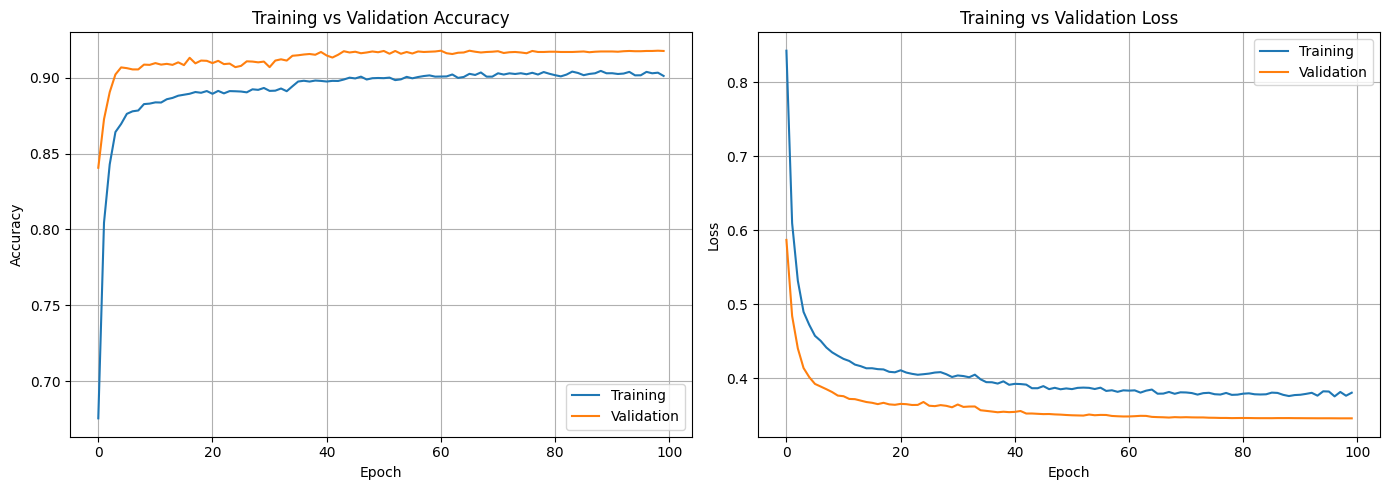

In [43]:
# Plot Training and Validation Accuracy and Loss to Check Model Learning and Overfitting.
import matplotlib.pyplot as plt

# Create two side-by-side plots for accuracy and loss.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot training and validation accuracy across epochs.
axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Plot training and validation loss across epochs.
axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

# Adjust spacing and display the plots.
plt.tight_layout()
plt.show()

In [44]:
#Evaluate the Deep Learning Model Using Test Metrics and a Classification Report.
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate class probabilities for the unseen test data.
test_probabilities = model.predict(X_test_processed, verbose=0)

# Convert predicted probabilities into engagement class labels.
test_predictions = np.argmax(test_probabilities, axis=1)

# Calculate test accuracy and macro-F1 score.
test_accuracy = accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(
    y_test, test_predictions, average="macro"
)

# Display the overall test performance.
print("DEEP LEARNING MODEL — TEST RESULTS")
print("-----------------------------------")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")

# Display precision, recall, F1-score, and support for each class.
print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

DEEP LEARNING MODEL — TEST RESULTS
-----------------------------------
Test Accuracy: 0.9207
Test Macro F1: 0.9163

Classification Report:
              precision    recall  f1-score   support

        High       0.93      0.89      0.91      1551
         Low       0.91      0.90      0.91      1548
      Medium       0.92      0.95      0.93      2907

    accuracy                           0.92      6006
   macro avg       0.92      0.91      0.92      6006
weighted avg       0.92      0.92      0.92      6006



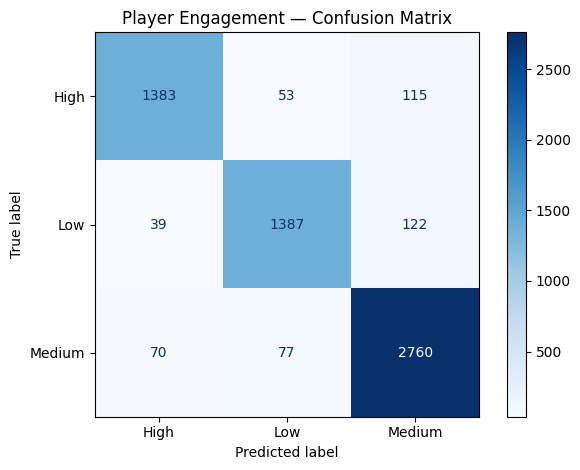

In [45]:
# Visualize the Confusion Matrix to Analyze Engagement Classification Errors.
# Generate a confusion matrix using the actual and predicted test labels.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    cmap="Blues",
    values_format="d"
)

# Add a title, adjust the layout, and display the confusion matrix.
plt.title("Player Engagement — Confusion Matrix")
plt.tight_layout()
plt.show()

In [46]:
# Compare Logistic Regression and Deep Learning Performance on the Test Dataset.
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Generate predictions from the Logistic Regression baseline on the test set.
baseline_test_predictions = baseline.predict(X_test_processed)

# Create a comparison table containing test accuracy and macro-F1 for both models.
comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Test Accuracy": accuracy_score(
            y_test, baseline_test_predictions
        ),
        "Test Macro F1": f1_score(
            y_test, baseline_test_predictions,
            average="macro"
        )
    },
    {
        "Model": "Deep Learning MLP",
        "Test Accuracy": accuracy_score(
            y_test, test_predictions
        ),
        "Test Macro F1": f1_score(
            y_test, test_predictions,
            average="macro"
        )
    }
])

# Display the model comparison metrics rounded to four decimal places.
display(comparison.round(4))

,Model,Test Accuracy,Test Macro F1
0,Logistic Regression,0.7814,0.7834
1,Deep Learning MLP,0.9207,0.9163


FINAL MODEL COMPARISON — UNTOUCHED TEST SET


,Model,Test Accuracy,Test Macro Precision,Test Macro Recall,Test Macro F1
0,MLP Neural Network,0.9207,0.9207,0.9124,0.9163
1,XGBoost,0.9113,0.9114,0.9028,0.9069
2,Random Forest,0.8991,0.9019,0.8884,0.8946
3,Logistic Regression,0.7814,0.7741,0.8051,0.7834



Logistic Regression — Test Classification Report
              precision    recall  f1-score   support

        High       0.79      0.91      0.84      1551
         Low       0.67      0.81      0.73      1548
      Medium       0.86      0.70      0.77      2907

    accuracy                           0.78      6006
   macro avg       0.77      0.81      0.78      6006
weighted avg       0.79      0.78      0.78      6006


MLP Neural Network — Test Classification Report
              precision    recall  f1-score   support

        High       0.93      0.89      0.91      1551
         Low       0.91      0.90      0.91      1548
      Medium       0.92      0.95      0.93      2907

    accuracy                           0.92      6006
   macro avg       0.92      0.91      0.92      6006
weighted avg       0.92      0.92      0.92      6006


Random Forest — Test Classification Report
              precision    recall  f1-score   support

        High       0.91      0.87      0

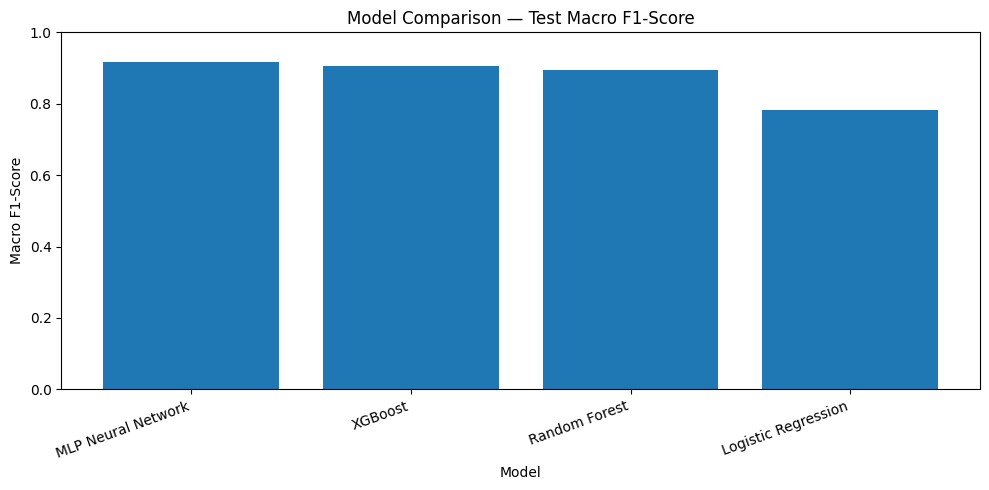


Best model by test macro F1: MLP Neural Network


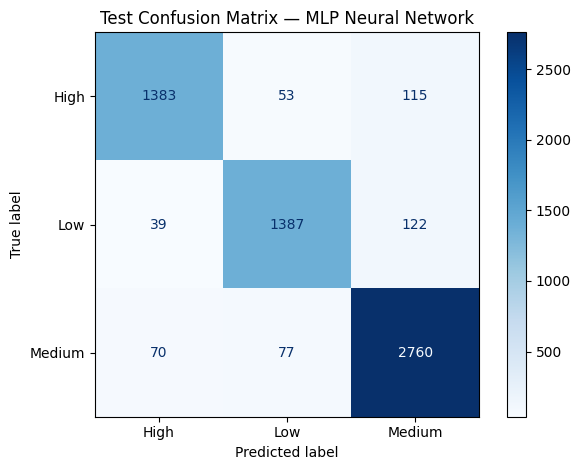

In [47]:
# FINAL TEST EVALUATION AND COMPARISON OF ALL FOUR MODELS

# SECTION 1: IMPORT REQUIRED METRICS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# SECTION 2: GENERATE TEST PREDICTIONS
# Use the same untouched test set for all four models.

# Logistic Regression predictions
lr_test_predictions = baseline.predict(X_test_processed)

# MLP predictions
mlp_test_probabilities = model.predict(X_test_processed, verbose=0)
mlp_test_predictions = np.argmax(mlp_test_probabilities, axis=1)

# Random Forest predictions
rf_test_predictions = random_forest.predict(X_test_processed)

# XGBoost predictions
xgb_test_predictions = xgboost_model.predict(X_test_processed).astype(int)

# SECTION 3: CALCULATE FINAL TEST METRICS
# Macro averages give equal weight to each engagement class.

test_models = {
    "Logistic Regression": lr_test_predictions,
    "MLP Neural Network": mlp_test_predictions,
    "Random Forest": rf_test_predictions,
    "XGBoost": xgb_test_predictions
}

test_results = []

for model_name, predictions in test_models.items():
    test_results.append({
        "Model": model_name,
        "Test Accuracy": accuracy_score(y_test, predictions),
        "Test Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Test Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Test Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

test_comparison = pd.DataFrame(test_results)
test_comparison = test_comparison.sort_values(
    "Test Macro F1", ascending=False
).reset_index(drop=True)

print("FINAL MODEL COMPARISON — UNTOUCHED TEST SET")
display(test_comparison.round(4))

# SECTION 4: DISPLAY CLASSIFICATION REPORTS
# Show precision, recall, and F1-score for each class.

class_names = list(label_encoder.classes_)
class_labels = np.arange(len(class_names))

for model_name, predictions in test_models.items():
    print(f"\n{model_name} — Test Classification Report")
    print(classification_report(
        y_test,
        predictions,
        labels=class_labels,
        target_names=class_names,
        zero_division=0
    ))

# SECTION 5: PLOT TEST MACRO F1 COMPARISON
plt.figure(figsize=(10, 5))
plt.bar(
    test_comparison["Model"],
    test_comparison["Test Macro F1"]
)
plt.title("Model Comparison — Test Macro F1-Score")
plt.ylabel("Macro F1-Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# SECTION 6: CONFUSION MATRIX FOR THE BEST TEST MODEL
# This identifies which engagement classes are misclassified.

best_model_name = test_comparison.iloc[0]["Model"]
best_predictions = test_models[best_model_name]

print(f"\nBest model by test macro F1: {best_model_name}")

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=class_labels
)

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display_plot.plot(cmap="Blues", values_format="d")
plt.title(f"Test Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


In [59]:

# PROJECT STEP: ERROR ANALYSIS — IDENTIFY AND EXPORT MISCLASSIFIED PLAYERS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

# Use the best model already selected by your test-set macro F1 score.
# Reuse test_models, best_model_name, y_test, X_test and label_encoder.
actual_labels = label_encoder.inverse_transform(y_test)
predicted_labels = label_encoder.inverse_transform(best_predictions)

# Build a table containing actual and predicted classes.
error_analysis = X_test.reset_index(drop=True).copy()
error_analysis["Actual_Engagement"] = actual_labels
error_analysis["Predicted_Engagement"] = predicted_labels
error_analysis["Correct_Prediction"] = (
    actual_labels == predicted_labels
)

# Add confidence when probabilities are available for the selected model.
if best_model_name == "MLP Neural Network":
    error_analysis["Prediction_Confidence"] = (
        mlp_test_probabilities.max(axis=1)
    )
elif best_model_name == "Logistic Regression":
    error_analysis["Prediction_Confidence"] = (
        baseline.predict_proba(X_test_processed).max(axis=1)
    )
elif best_model_name == "Random Forest":
    error_analysis["Prediction_Confidence"] = (
        random_forest.predict_proba(X_test_processed).max(axis=1)
    )
elif best_model_name == "XGBoost":
    error_analysis["Prediction_Confidence"] = (
        xgboost_model.predict_proba(X_test_processed).max(axis=1)
    )

# Select only incorrect predictions for detailed inspection.
misclassified = error_analysis.loc[
    ~error_analysis["Correct_Prediction"]
].copy()

print("Selected model:", best_model_name)
print("Total test samples:", len(error_analysis))
print("Incorrect predictions:", len(misclassified))
print(
    "Error rate:",
    f"{len(misclassified) / len(error_analysis):.2%}"
)

display(misclassified.head(20))

# Summarize which actual classes are most frequently misclassified.
print("Misclassifications by actual class:")
display(
    misclassified["Actual_Engagement"]
    .value_counts()
    .rename_axis("Actual Class")
    .reset_index(name="Incorrect Predictions")
)

# Summarize the actual-class versus predicted-class error patterns.
error_pairs = (
    misclassified.groupby(
        ["Actual_Engagement", "Predicted_Engagement"]
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("Most frequent misclassification pairs:")
display(error_pairs)

# Save detailed results for your report.
import os
os.makedirs("outputs/results", exist_ok=True)

misclassified.to_csv(
    "outputs/results/misclassified_players.csv", index=False
)
error_pairs.to_csv(
    "outputs/results/misclassification_summary.csv", index=False
)

print("Error-analysis CSV files saved in outputs/results/")


Selected model: MLP Neural Network
Total test samples: 6006
Incorrect predictions: 476
Error rate: 7.93%


,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,Actual_Engagement,Predicted_Engagement,Correct_Prediction,Prediction_Confidence
24,33,Female,Other,Action,14.890332,0,Easy,1,170,85,27,Low,Medium,False,0.521614
33,17,Male,Europe,Strategy,8.644038,0,Easy,3,117,1,11,Medium,Low,False,0.645249
59,49,Female,Asia,Action,22.572659,0,Easy,17,21,69,0,Low,Medium,False,0.582147
81,37,Female,USA,RPG,22.774269,0,Hard,7,38,33,43,High,Medium,False,0.552118
83,39,Male,Asia,Sports,13.098169,0,Medium,12,176,14,26,Medium,High,False,0.945722
104,39,Male,Asia,Sports,3.367562,1,Medium,10,56,7,26,Low,Medium,False,0.950024
115,21,Male,Europe,Strategy,11.188230,0,Hard,15,134,34,13,Medium,High,False,0.951545
128,49,Male,USA,Simulation,23.987963,1,Easy,1,169,88,42,High,Medium,False,0.771337
136,48,Male,Asia,Simulation,2.081759,0,Easy,7,35,2,2,High,Low,False,0.893148
170,38,Male,USA,Simulation,15.400018,0,Easy,9,12,86,48,Medium,Low,False,0.651663


Misclassifications by actual class:


,Actual Class,Incorrect Predictions
0,High,168
1,Low,161
2,Medium,147


Most frequent misclassification pairs:


,Actual_Engagement,Predicted_Engagement,Count
3,Low,Medium,122
1,High,Medium,115
5,Medium,Low,77
4,Medium,High,70
0,High,Low,53
2,Low,High,39


Error-analysis CSV files saved in outputs/results/


In [60]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=error_pairs)

https://docs.google.com/spreadsheets/d/18QaG06q_qTOfeghKgI8Du0iHkCNyVtY4sB0whfAJeC0/edit#gid=0


In [65]:

# PROJECT STEP: REPRODUCIBILITY — SAVE ENVIRONMENT AND EXPERIMENT SETTINGS

import os
import sys
import json
import platform
import subprocess
from pathlib import Path
import importlib.metadata as metadata
from datetime import datetime, timezone
os.makedirs("outputs/results", exist_ok=True)

# Capture versions of the main libraries used in the project.
packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "tensorflow",
    "keras",
    "xgboost",
    "matplotlib",
    "seaborn",
    "joblib",
    "reportlab",
    "ipykernel",
    "jupyter"
]

package_versions = {}

for package in packages:
    try:
        package_versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        package_versions[package] = "Not installed"

# Record the configuration actually used in the notebook.
experiment_details = {
    "project": "Horizon: Early Detection of Player Disengagement",
    "recorded_at_utc": datetime.now(timezone.utc).isoformat() + "Z",
    "python_version": sys.version,
    "platform": platform.platform(),
    "random_seed": 42,
    "dataset_rows_after_duplicate_removal": int(len(df)),
    "original_dataset_columns": int(df.shape[1]),
    "predictor_columns_before_encoding": int(X.shape[1]),
    "processed_feature_count": int(X_train_processed.shape[1]),
    "target_column": "EngagementLevel",
    "classes": label_encoder.classes_.tolist(),
    "split_percentages": {
        "train": 70,
        "validation": 15,
        "test": 15
    },
    "mlp_configuration": {
        "hidden_layers": [64, 32],
        "activation": "ReLU",
        "output_activation": "Softmax",
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "loss": "sparse_categorical_crossentropy",
        "batch_size": 64,
        "maximum_epochs": 100,
        "early_stopping_patience": 10,
        "reduce_lr_patience": 4,
        "dropout_rates": [0.30, 0.20],
        "l2_regularization": 0.001
    },
    "packages": package_versions
}

output_path = Path("outputs/results/reproducibility_details.json")
output_path.write_text(
    json.dumps(experiment_details, indent=2),
    encoding="utf-8"
)

# Save a pip package snapshot as well.
try:
    result = subprocess.run(
        [sys.executable, "-m", "pip", "freeze"],
        capture_output=True,
        text=True,
        check=True
    )
    Path("outputs/results/environment_requirements.txt").write_text(
        result.stdout,
        encoding="utf-8"
    )
    print("Full package snapshot saved.")
except (subprocess.CalledProcessError, OSError) as exc:
    print("Could not create pip snapshot:", exc)

print("Reproducibility details saved to:", output_path)
print(json.dumps(experiment_details, indent=2))


Full package snapshot saved.
Reproducibility details saved to: outputs/results/reproducibility_details.json
{
  "project": "Horizon: Early Detection of Player Disengagement",
  "recorded_at_utc": "2026-10-11T18:43:37.669607+00:00Z",
  "python_version": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "random_seed": 42,
  "dataset_rows_after_duplicate_removal": 40034,
  "original_dataset_columns": 13,
  "predictor_columns_before_encoding": 11,
  "processed_feature_count": 21,
  "target_column": "EngagementLevel",
  "classes": [
    "High",
    "Low",
    "Medium"
  ],
  "split_percentages": {
    "train": 70,
    "validation": 15,
    "test": 15
  },
  "mlp_configuration": {
    "hidden_layers": [
      64,
      32
    ],
    "activation": "ReLU",
    "output_activation": "Softmax",
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "sparse_categorical_crossentropy",
    "batch_size": 64,
    "maximum_epochs": 1

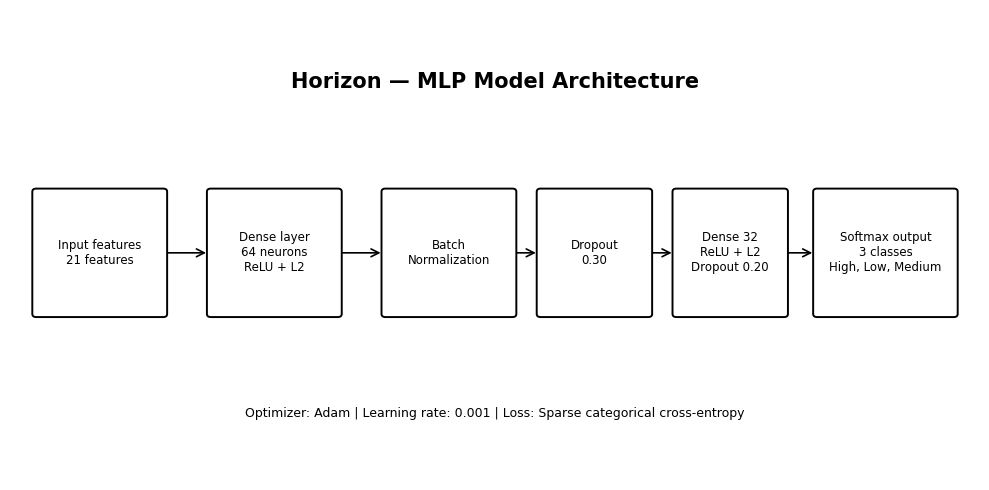

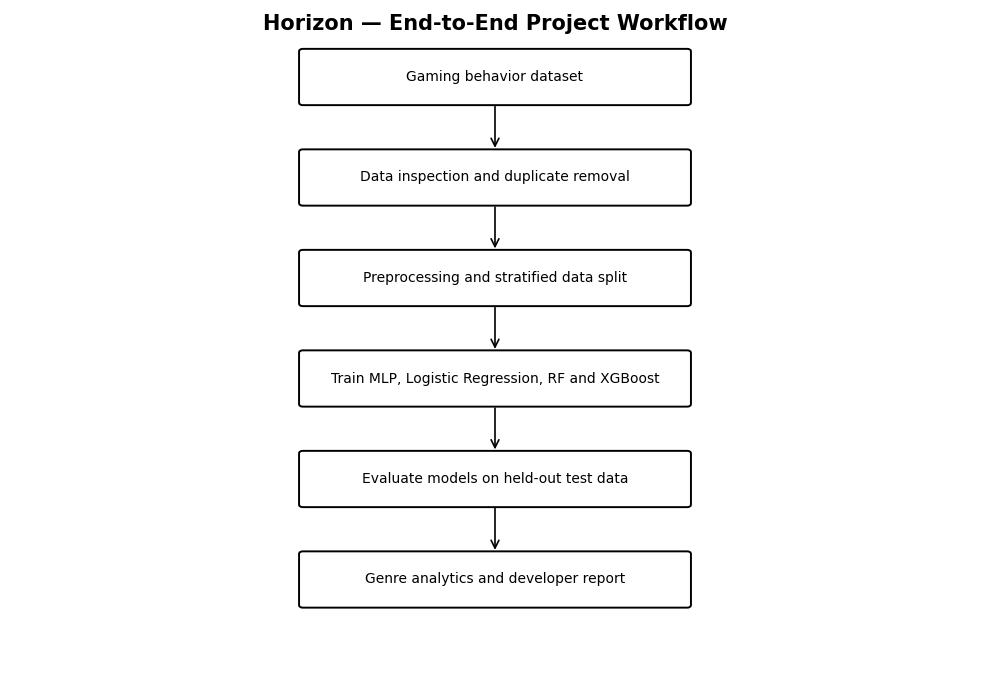

Diagrams saved:
 - outputs/charts/mlp_architecture.png
 - outputs/charts/project_workflow.png


In [63]:

# PROJECT STEP: GENERATE AND SAVE MLP ARCHITECTURE AND SYSTEM WORKFLOW DIAGRAMS

import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

os.makedirs("outputs/charts", exist_ok=True)

def draw_box(ax, x, y, width, height, text, fontsize=10):
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.02,rounding_size=0.04",
        linewidth=1.4,
        facecolor="white",
        edgecolor="black"
    )
    ax.add_patch(box)
    ax.text(
        x + width / 2, y + height / 2, text,
        ha="center", va="center", fontsize=fontsize,
        wrap=True
    )

def draw_arrow(ax, x1, y1, x2, y2):
    arrow = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="->", mutation_scale=14, linewidth=1.2
    )
    ax.add_patch(arrow)

# DIAGRAM A: MLP neural network architecture.
fig, ax = plt.subplots(figsize=(10, 5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

architecture = [
    (0.25, 2.1, 1.35, 1.6,
     f"Input features\n{X_train_processed.shape[1]} features"),
    (2.05, 2.1, 1.35, 1.6,
     "Dense layer\n64 neurons\nReLU + L2"),
    (3.85, 2.1, 1.35, 1.6,
     "Batch\nNormalization"),
    (5.45, 2.1, 1.15, 1.6,
     "Dropout\n0.30"),
    (6.85, 2.1, 1.15, 1.6,
     "Dense 32\nReLU + L2\nDropout 0.20"),
    (8.3, 2.1, 1.45, 1.6,
     f"Softmax output\n{len(label_encoder.classes_)} classes\n"
     + ", ".join(label_encoder.classes_))
]

for x, y, w, h, text in architecture:
    draw_box(ax, x, y, w, h, text, fontsize=8.5)

for i in range(len(architecture) - 1):
    x, y, w, h, _ = architecture[i]
    nx, ny, nw, nh, _ = architecture[i + 1]
    draw_arrow(ax, x + w, y + h / 2, nx, ny + nh / 2)

ax.text(
    5, 5.0, "Horizon — MLP Model Architecture",
    ha="center", fontsize=15, fontweight="bold"
)
ax.text(
    5, 0.8,
    "Optimizer: Adam | Learning rate: 0.001 | "
    "Loss: Sparse categorical cross-entropy",
    ha="center", fontsize=9
)

plt.tight_layout()
fig.savefig(
    "outputs/charts/mlp_architecture.png",
    dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# DIAGRAM B: Overall project workflow.
fig, ax = plt.subplots(figsize=(10, 7))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

workflow = [
    (3.0, 8.6, 4.0, 0.8, "Gaming behavior dataset"),
    (3.0, 7.1, 4.0, 0.8, "Data inspection and duplicate removal"),
    (3.0, 5.6, 4.0, 0.8, "Preprocessing and stratified data split"),
    (3.0, 4.1, 4.0, 0.8, "Train MLP, Logistic Regression, RF and XGBoost"),
    (3.0, 2.6, 4.0, 0.8, "Evaluate models on held-out test data"),
    (3.0, 1.1, 4.0, 0.8, "Genre analytics and developer report")
]

for x, y, w, h, text in workflow:
    draw_box(ax, x, y, w, h, text, fontsize=10)

for i in range(len(workflow) - 1):
    x, y, w, h, _ = workflow[i]
    nx, ny, nw, nh, _ = workflow[i + 1]
    draw_arrow(ax, x + w / 2, y, nx + nw / 2, ny + nh)

ax.text(
    5, 9.7, "Horizon — End-to-End Project Workflow",
    ha="center", fontsize=15, fontweight="bold"
)

plt.tight_layout()
fig.savefig(
    "outputs/charts/project_workflow.png",
    dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Diagrams saved:")
print(" - outputs/charts/mlp_architecture.png")
print(" - outputs/charts/project_workflow.png")


,Feature,Importance
3,numeric__SessionsPerWeek,0.369272
4,numeric__AvgSessionDurationMinutes,0.285681
6,numeric__AchievementsUnlocked,0.009162
5,numeric__PlayerLevel,0.008681
7,categorical__Gender_Female,0.008044
8,categorical__Gender_Male,0.007264
20,categorical__GameDifficulty_Medium,0.005176
19,categorical__GameDifficulty_Hard,0.003987
17,categorical__GameGenre_Strategy,0.003404
18,categorical__GameDifficulty_Easy,0.002914


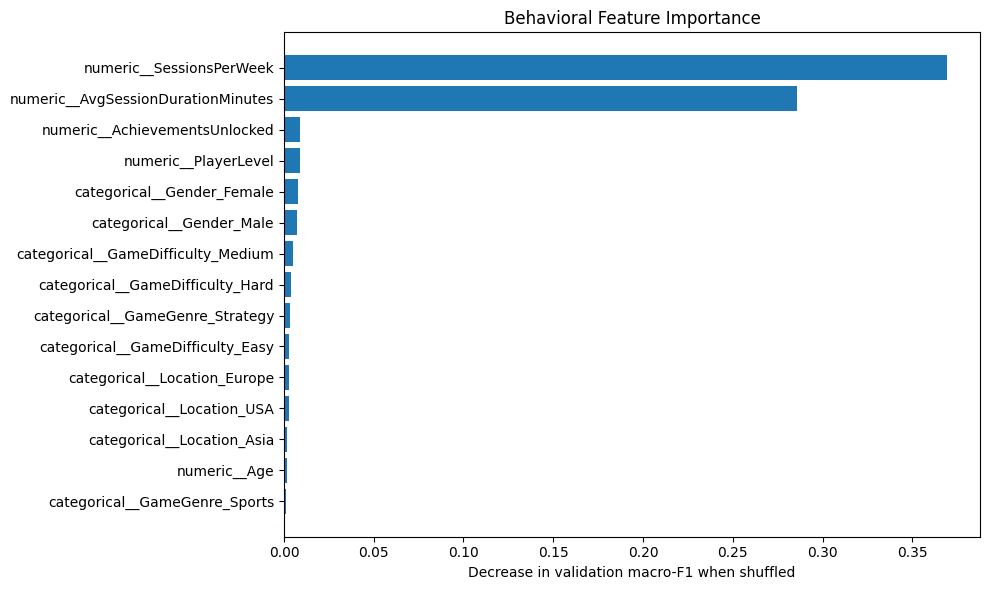

In [48]:
# Identify and Visualize Important Player Behavior Features Using Permutation Importance.
from sklearn.inspection import permutation_importance

# Measure how much validation macro-F1 decreases when each feature is shuffled.
importance = permutation_importance(
    baseline,
    X_val_processed,
    y_val,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Retrieve the processed feature names, or create fallback names if unavailable.
try:
    feature_names = preprocessor.get_feature_names_out()
except Exception:
    feature_names = [
        f"Feature_{i}"
        for i in range(X_val_processed.shape[1])
    ]

# Create a table of features and their average permutation importance scores.
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

# Display the 15 features with the highest importance scores.
display(importance_df.head(15))

# Sort the top features for a clearer horizontal bar chart.
top_features = importance_df.head(15).sort_values("Importance")

# Plot the importance scores of the selected features.
plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Decrease in validation macro-F1 when shuffled")
plt.title("Behavioral Feature Importance")
plt.tight_layout()
plt.show()

In [49]:
# Generate Test Predictions, Class Probabilities, and Preliminary Low-Engagement Review Flags.
# Copy the original test features into a results table.
results = X_test.reset_index(drop=True).copy()

# Add the actual and predicted engagement labels.
results["Actual_Engagement"] = (
    label_encoder.inverse_transform(y_test)
)
results["Predicted_Engagement"] = (
    label_encoder.inverse_transform(test_predictions)
)

# Record the highest predicted class probability for each player.
results["Prediction_Confidence"] = (
    test_probabilities.max(axis=1)
)

# Add the predicted probability for each engagement class.
for i, class_name in enumerate(label_encoder.classes_):
    results[f"Probability_{class_name}"] = test_probabilities[:, i]

# Flag predictions with a low-engagement probability of at least 50%.
if "Low" in label_encoder.classes_:
    low_index = list(label_encoder.classes_).index("Low")
    results["Low_Engagement_Probability"] = (
        test_probabilities[:, low_index]
    )
    results["Review_Flag"] = (
        test_probabilities[:, low_index] >= 0.50
    )

# Display the first 10 prediction records.
display(results.head(10))

# Summarize the number of predictions in each engagement category.
print("Predicted engagement distribution:")
print(results["Predicted_Engagement"].value_counts())

,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,Actual_Engagement,Predicted_Engagement,Prediction_Confidence,Probability_High,Probability_Low,Probability_Medium,Low_Engagement_Probability,Review_Flag
0,34,Female,Asia,Action,4.438101,0,Easy,17,33,29,16,Medium,Medium,0.955199,0.018168,0.026633,0.955199,0.026633,False
1,25,Male,USA,Strategy,7.976964,1,Easy,12,35,22,26,Medium,Medium,0.897162,0.032670,0.070168,0.897162,0.070168,False
2,47,Female,Other,Strategy,13.194133,0,Medium,14,63,29,31,Medium,Medium,0.959099,0.018454,0.022447,0.959099,0.022447,False
3,22,Male,Europe,Sports,21.207082,0,Easy,7,125,84,3,Medium,Medium,0.953313,0.020361,0.026326,0.953313,0.026326,False
4,27,Male,Asia,Sports,17.079068,0,Hard,9,140,73,31,Medium,Medium,0.615673,0.330930,0.053396,0.615673,0.053396,False
5,16,Female,Asia,Sports,14.244222,0,Easy,8,24,73,25,Low,Low,0.836712,0.031922,0.836712,0.131366,0.836712,True
6,34,Female,Europe,Sports,5.233814,0,Hard,2,22,67,19,Low,Low,0.913700,0.042100,0.913700,0.044199,0.913700,True
7,45,Male,USA,Action,2.056157,1,Medium,18,57,35,28,Medium,Medium,0.885258,0.072968,0.041774,0.885258,0.041774,False
8,39,Female,Asia,Strategy,13.301180,0,Easy,7,78,24,21,Medium,Medium,0.949775,0.018755,0.031470,0.949775,0.031470,False
9,47,Male,USA,Strategy,13.231107,0,Medium,11,46,75,25,Medium,Medium,0.944718,0.018960,0.036322,0.944718,0.036322,False


Predicted engagement distribution:
Predicted_Engagement
Medium    2997
Low       1517
High      1492
Name: count, dtype: int64


In [50]:
# Generate Player Engagement Insights, Developer Recommendations, and a Report.
import numpy as np
import pandas as pd
import os

# Define rules to generate game-design recommendations based on predicted engagement.
def generate_recommendations(engagement, player_data, important_features):
    recommendations = []

    # Convert feature names into a consistent format for matching.
    features = [
        str(f).lower().replace(" ", "_")
        for f in important_features
    ]

    # Recommend areas for investigation based on predicted engagement.
    if engagement == "Low":
        recommendations.extend([
            {
                "Priority": "High",
                "Focus Area": "Player progression",
                "Suggestion": "Investigate progression barriers, level difficulty, and whether players have clear next goals."
            },
            {
                "Priority": "High",
                "Focus Area": "Rewards and achievements",
                "Suggestion": "Review achievement accessibility, reward relevance, and milestone design."
            },
            {
                "Priority": "Medium",
                "Focus Area": "Gameplay experience",
                "Suggestion": "Investigate repetitive gameplay and test optional challenges or varied content."
            }
        ])

    elif engagement == "Medium":
        recommendations.extend([
            {
                "Priority": "High",
                "Focus Area": "Progression and goals",
                "Suggestion": "Test clearer milestones, balanced challenges, and meaningful progression rewards."
            },
            {
                "Priority": "Medium",
                "Focus Area": "Player experience",
                "Suggestion": "Explore optional missions, varied gameplay, and feedback on player satisfaction."
            }
        ])

    else:
        recommendations.extend([
            {
                "Priority": "Medium",
                "Focus Area": "Sustaining engagement",
                "Suggestion": "Maintain balanced difficulty, introduce optional content, and monitor changes in player behavior."
            },
            {
                "Priority": "Low",
                "Focus Area": "Long-term experience",
                "Suggestion": "Test new challenges and content without making the game unnecessarily repetitive or demanding."
            }
        ])

    # Link important features to possible game-design areas for further investigation.
    for feature in features[:5]:
        if any(word in feature for word in ["playtime", "session", "duration", "frequency"]):
            area = "Session behavior"
            suggestion = "Analyze session length and frequency patterns. Use time-series data to detect actual changes over time."

        elif any(word in feature for word in ["achievement", "reward"]):
            area = "Achievements and rewards"
            suggestion = "Investigate whether achievement design and rewards are associated with different engagement categories."

        elif any(word in feature for word in ["level", "progress", "experience"]):
            area = "Progression system"
            suggestion = "Review level progression, difficulty balance, and opportunities for players to advance."

        elif any(word in feature for word in ["purchase", "spend", "transaction"]):
            area = "In-game purchases"
            suggestion = "Evaluate whether purchasing behavior relates to engagement without making spending necessary for a good experience."

        else:
            area = f"Behavior: {feature}"
            suggestion = f"Investigate how {feature} relates to engagement and validate possible improvements through testing."

        recommendations.append({
            "Priority": "Investigate",
            "Focus Area": area,
            "Suggestion": suggestion
        })

    # Remove duplicate recommendations.
    unique = []
    seen = set()

    for item in recommendations:
        key = (item["Focus Area"], item["Suggestion"])
        if key not in seen:
            seen.add(key)
            unique.append(item)

    return unique


# Select a test record and predict its engagement category.
sample_index = 0
sample = X_test_processed[sample_index:sample_index + 1]
probabilities = model.predict(sample, verbose=0)[0]

# Identify the predicted engagement class and its probability.
predicted_index = int(np.argmax(probabilities))
predicted_engagement = label_encoder.inverse_transform([predicted_index])[0]
confidence = float(probabilities[predicted_index])

# Reuse the feature importance results calculated in Step 11.
top_features = importance_df.head(10)["Feature"].tolist()

# Generate recommendations for the selected test record.
recommendations = generate_recommendations(
    predicted_engagement,
    X_test.iloc[sample_index],
    top_features
)

# Display the engagement prediction, class probabilities, and important features.
print("=" * 60)
print("PLAYER ENGAGEMENT AND RECOMMENDATION REPORT")
print("=" * 60)
print(f"\nPredicted Engagement: {predicted_engagement}")
print(f"Prediction Confidence: {confidence:.2%}")

print("\nClass Probabilities:")
for class_name, probability in zip(label_encoder.classes_, probabilities):
    print(f"{class_name}: {probability:.2%}")

print("\nTOP BEHAVIORAL FEATURES")
print("-" * 60)
print(importance_df.head(10).to_string(index=False))

# Convert recommendations into a table and display them.
recommendations_df = pd.DataFrame(recommendations)

print("\nRECOMMENDATIONS FOR GAME DEVELOPERS")
print("-" * 60)

for i, rec in enumerate(recommendations, start=1):
    print(f"\n{i}. {rec['Focus Area']}")
    print(f"   Priority: {rec['Priority']}")
    print(f"   Suggestion: {rec['Suggestion']}")

# Save the generated recommendations to a CSV file.
os.makedirs("outputs/results", exist_ok=True)
recommendations_df.to_csv(
    "outputs/results/player_recommendations.csv",
    index=False
)

print("\nReport saved successfully!")
print("outputs/results/player_recommendations.csv")

PLAYER ENGAGEMENT AND RECOMMENDATION REPORT

Predicted Engagement: Medium
Prediction Confidence: 95.52%

Class Probabilities:
High: 1.82%
Low: 2.66%
Medium: 95.52%

TOP BEHAVIORAL FEATURES
------------------------------------------------------------
                           Feature  Importance
          numeric__SessionsPerWeek    0.369272
numeric__AvgSessionDurationMinutes    0.285681
     numeric__AchievementsUnlocked    0.009162
              numeric__PlayerLevel    0.008681
        categorical__Gender_Female    0.008044
          categorical__Gender_Male    0.007264
categorical__GameDifficulty_Medium    0.005176
  categorical__GameDifficulty_Hard    0.003987
   categorical__GameGenre_Strategy    0.003404
  categorical__GameDifficulty_Easy    0.002914

RECOMMENDATIONS FOR GAME DEVELOPERS
------------------------------------------------------------

1. Progression and goals
   Priority: High
   Suggestion: Test clearer milestones, balanced challenges, and meaningful progression rew

In [51]:
# STEP 15: BUILD ENGAGEMENT CLASS PROFILES WITHOUT TEST-DATA LEAKAGE
# Calculate numerical feature averages using training records only.

# Import pandas and NumPy for profile calculation.
import numpy as np
import pandas as pd

# Reconstruct a training-only analysis table and restore readable target labels.
analysis_df = X_train.copy()
analysis_df["EngagementLevel"] = label_encoder.inverse_transform(y_train)

# Select numeric behavioral features, excluding the target label.
numeric_features = analysis_df.select_dtypes(include=np.number).columns.tolist()

# Calculate average numeric behavior for each class using training data only.
class_profiles = analysis_df.groupby("EngagementLevel")[numeric_features].mean()

# Display the training-only class profiles used by the recommendation tools.
print("TRAINING-ONLY AVERAGE BEHAVIOR BY ENGAGEMENT LEVEL")
display(class_profiles.round(2))

# Note: these are descriptive averages, not causal explanations or future-risk estimates.


TRAINING-ONLY AVERAGE BEHAVIOR BY ENGAGEMENT LEVEL


,Age,PlayTimeHours,InGamePurchases,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked
EngagementLevel,,,,,,,
High,31.92,12.16,0.21,14.28,132.07,50.70,25.21
Low,31.90,12.05,0.19,4.53,66.85,46.09,22.58
Medium,32.19,11.97,0.20,9.52,89.83,50.91,25.15


In [52]:
# Step 16: Create a Reusable Function to Predict New Player Engagement and Generate Developer Suggestions.
import pandas as pd
import numpy as np

# Define a function that accepts player details and predicts engagement.
def analyze_new_player(player_details):

    # Convert the player details into a DataFrame with the expected feature columns.
    player_df = pd.DataFrame([player_details])

    # Transform the input using the preprocessing pipeline fitted during training.
    processed = preprocessor.transform(player_df)

    # Predict engagement probabilities and identify the most likely class.
    probabilities = model.predict(processed, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    engagement = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    # Display the predicted engagement class and confidence score.
    print("=" * 50)
    print("PLAYER ENGAGEMENT REPORT")
    print("=" * 50)
    print("Predicted engagement:", engagement)
    print(f"Prediction confidence: {probabilities[predicted_index]:.2%}")

    # Display the predicted probability for every engagement class.
    print("\nClass probabilities:")
    for name, probability in zip(
        label_encoder.classes_, probabilities
    ):
        print(f"{name}: {probability:.2%}")

    # Generate suggestions based on the predicted engagement category.
    print("\nDEVELOPER SUGGESTIONS")

    if engagement == "Low":
        print("- Investigate progression barriers and difficulty balance.")
        print("- Review achievement accessibility and reward design.")
        print("- Gather feedback about repetitive or frustrating gameplay.")

    elif engagement == "Medium":
        print("- Investigate progression and achievement opportunities.")
        print("- Evaluate gameplay variety and challenge balance.")
        print("- Test improvements and measure player feedback.")

    else:
        print("- Maintain balanced challenges and meaningful progression.")
        print("- Evaluate optional content and new gameplay experiences.")
        print("- Monitor engagement patterns over time.")

    # Clarify that suggestions are hypotheses rather than proven interventions.
    print("\nThese suggestions are hypotheses to investigate,")
    print("not proof that a particular change will improve engagement.")

    # Return the predicted class and its probability distribution.
    return engagement, probabilities


# Test the function using one record from the held-out test dataset.
example_player = X_test.iloc[0].to_dict()
analyze_new_player(example_player)

PLAYER ENGAGEMENT REPORT
Predicted engagement: Medium
Prediction confidence: 95.52%

Class probabilities:
High: 1.82%
Low: 2.66%
Medium: 95.52%

DEVELOPER SUGGESTIONS
- Investigate progression and achievement opportunities.
- Evaluate gameplay variety and challenge balance.
- Test improvements and measure player feedback.

These suggestions are hypotheses to investigate,
not proof that a particular change will improve engagement.


('Medium', array([0.01816799, 0.02663278, 0.9551992 ], dtype=float32))

In [53]:
# STEP 18: INTERACTIVE PLAYER ENGAGEMENT ANALYZER
# Purpose: Predict player engagement, compare behavioral patterns,
# generate developer suggestions, and save analysis results.

# SECTION 1: IMPORT LIBRARIES AND CHECK REQUIRED OBJECTS
# Import libraries for data processing, interactive widgets, and output display.
import os
import numpy as np
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output

# Check that the trained model, preprocessing pipeline, label encoder,
# training features, and class profiles are available.
required_objects = [
    "X_train",
    "preprocessor",
    "model",
    "label_encoder",
    "class_profiles"
]

# Identify missing objects and stop execution if earlier cells were not run.
missing = [
    name for name in required_objects
    if name not in globals()
]

if missing:
    raise NameError(
        "Run the earlier notebook cells first. Missing: "
        + ", ".join(missing)
    )

# Store the original training feature names and column order.
feature_columns = list(X_train.columns)

# Define behavioral features and corresponding developer suggestions.
recommendation_rules = {
    "PlayerLevel": (
        "Player progression",
        "Review progression milestones and difficulty balance."
    ),
    "AchievementsUnlocked": (
        "Achievements and rewards",
        "Review achievement accessibility and reward relevance."
    ),
    "SessionsPerWeek": (
        "Session patterns",
        "Investigate session frequency and gather player feedback."
    ),
    "AvgSessionDurationMinutes": (
        "Session experience",
        "Investigate session patterns without assuming longer "
        "sessions are automatically better."
    ),
    "InGamePurchases": (
        "Purchasing behavior",
        "Investigate purchasing patterns without encouraging spending."
    )
}

# SECTION 2: CREATE THE INTERACTIVE INPUT FORM
# Generate numeric input fields and categorical dropdown menus
# for the features required by the trained model.
controls = {}

for col in feature_columns:

    # Use a numeric input field with the training median as its default.
    if pd.api.types.is_numeric_dtype(X_train[col]):
        values = pd.to_numeric(
            X_train[col], errors="coerce"
        ).dropna()

        if values.empty:
            continue

        default_value = float(values.median())

        controls[col] = widgets.FloatText(
            value=default_value,
            description=col,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="500px")
        )

    # Use a dropdown populated with the training data's categories.
    else:
        options = X_train[col].dropna().unique().tolist()

        if len(options) > 0:
            controls[col] = widgets.Dropdown(
                options=options,
                value=options[0],
                description=col,
                style={"description_width": "initial"},
                layout=widgets.Layout(width="500px")
            )

# Verify that every required feature has an input control.
missing_controls = [
    col for col in feature_columns
    if col not in controls
]

if missing_controls:
    raise ValueError(
        "Could not create input controls for: "
        + ", ".join(missing_controls)
    )

# Create the button used to start player analysis.
predict_button = widgets.Button(
    description="Analyze Player",
    button_style="primary",
    icon="search",
    layout=widgets.Layout(width="200px")
)

# Create an output area for prediction results and recommendations.
output = widgets.Output()

# SECTION 3: DEFINE THE PLAYER ANALYSIS FUNCTION
# Transform player inputs, predict engagement, display probabilities,
# compare behavioral features, and save the results.
def analyze_player(player_input):

    # Convert the input dictionary into a DataFrame with training columns.
    player_df = pd.DataFrame(
        [player_input],
        columns=feature_columns
    )

    # Apply the preprocessing pipeline fitted on the training data.
    processed_player = preprocessor.transform(player_df)

    # Predict the probability of each engagement class.
    probabilities = model.predict(
        processed_player,
        verbose=0
    )[0]

    # Select the class with the highest predicted probability.
    predicted_index = int(np.argmax(probabilities))

    # Convert the predicted numerical index into its original class label.
    engagement = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    # Store the probability associated with the predicted class.
    confidence = float(probabilities[predicted_index])

    # SECTION 3A: DISPLAY THE PREDICTION
    # Print the predicted engagement class and individual class probabilities.
    print("=" * 60)
    print("PLAYER ENGAGEMENT REPORT")
    print("=" * 60)

    print(f"Predicted engagement: {engagement}")
    print(f"Prediction confidence: {confidence:.2%}")

    print("\nCLASS PROBABILITIES")

    for class_name, probability in zip(
        label_encoder.classes_, probabilities
    ):
        print(f"{class_name}: {probability:.2%}")

    # SECTION 3B: GENERATE GENERAL DEVELOPER SUGGESTIONS
    # Select general investigation suggestions based on predicted engagement.
    print("\nGENERAL DEVELOPER SUGGESTIONS")

    if engagement == "Low":
        general_suggestions = [
            "Investigate possible progression barriers.",
            "Review achievement accessibility and reward design.",
            "Collect feedback about frustrating or repetitive gameplay."
        ]

    elif engagement == "Medium":
        general_suggestions = [
            "Investigate progression and achievement opportunities.",
            "Evaluate gameplay variety and challenge balance.",
            "Test improvements and measure player feedback."
        ]

    else:
        general_suggestions = [
            "Maintain balanced challenges and meaningful progression.",
            "Evaluate optional content and new gameplay experiences.",
            "Monitor engagement patterns and player feedback."
        ]

    # Display the selected general suggestions.
    for suggestion in general_suggestions:
        print("- " + suggestion)

    # SECTION 3C: COMPARE BEHAVIOR WITH CLASS AVERAGES
    # Compare selected player features with the predicted class profile.
    # Flag differences greater than 20% for further investigation.
    print("\nBEHAVIORAL DIFFERENCES TO INVESTIGATE")

    profile = class_profiles.loc[engagement]
    findings = []

    for feature, (area, suggestion) in recommendation_rules.items():

        # Skip features unavailable in the input or class profile.
        if feature not in player_df.columns:
            continue

        if feature not in profile.index:
            continue

        # Retrieve the player's value and the corresponding class average.
        value = player_df.iloc[0][feature]
        average = profile[feature]

        # Skip comparisons involving missing values.
        if pd.isna(value) or pd.isna(average):
            continue

        # Calculate the relative difference from the class average.
        if average != 0:
            difference = (value - average) / abs(average)
        else:
            difference = 0

        # Categorize differences that exceed the 20% threshold.
        if difference < -0.20:
            status = "Below predicted-class average"

        elif difference > 0.20:
            status = "Above predicted-class average"

        else:
            continue

        # Store each flagged feature and its suggested investigation.
        findings.append({
            "Engagement": engagement,
            "PredictionConfidence": round(confidence, 4),
            "Feature": feature,
            "FocusArea": area,
            "PlayerValue": value,
            "ClassAverage": round(float(average), 2),
            "Comparison": status,
            "DeveloperSuggestion": suggestion
        })

    # Display the behavioral comparison results.
    if findings:
        findings_df = pd.DataFrame(findings)

        for _, row in findings_df.iterrows():
            print(f"\nFocus area: {row['FocusArea']}")
            print(f"Feature: {row['Feature']}")
            print(f"Player value: {row['PlayerValue']}")
            print(f"Class average: {row['ClassAverage']}")
            print(f"Comparison: {row['Comparison']}")
            print(
                "Suggested action: "
                + row["DeveloperSuggestion"]
            )

    else:
        # Create an empty results table when no features are flagged.
        findings_df = pd.DataFrame()

        print(
            "No large differences found for the selected features "
            "using the 20% comparison threshold."
        )

    # Explain that the comparisons are exploratory, not causal evidence.
    print("\nIMPORTANT LIMITATION")
    print(
        "These comparisons identify areas to investigate. They do "
        "not prove causes of engagement or predict future disengagement."
    )

    # SECTION 3D: SAVE PREDICTION AND RECOMMENDATION FILES
    # Create the output directory if it does not already exist.
    os.makedirs("outputs/results", exist_ok=True)

    # Combine input features, predicted engagement, confidence,
    # and class probabilities into one prediction record.
    prediction_result = pd.DataFrame([{
        **player_input,
        "PredictedEngagement": engagement,
        "PredictionConfidence": confidence,
        **{
            f"Probability_{name}": float(prob)
            for name, prob in zip(
                label_encoder.classes_, probabilities
            )
        }
    }])

    # Export the current player's prediction to CSV.
    prediction_result.to_csv(
        "outputs/results/interactive_player_prediction.csv",
        index=False
    )

    # Export recommendations only when behavioral differences are found.
    if not findings_df.empty:
        findings_df.to_csv(
            "outputs/results/interactive_player_recommendations.csv",
            index=False
        )

    # Confirm the output directory containing the saved files.
    print("\nFiles saved in outputs/results/")

    # Return results so other notebook cells can reuse them.
    return {
        "engagement": engagement,
        "confidence": confidence,
        "probabilities": probabilities,
        "recommendations": findings_df
    }


# SECTION 4: CONNECT THE BUTTON TO THE ANALYSIS FUNCTION
# Read the current form values and run the analysis when clicked.
def on_predict_clicked(button):

    # Clear previous output before showing the latest analysis.
    with output:
        clear_output(wait=True)

        try:
            # Collect the current value of every model input feature.
            player_input = {
                col: controls[col].value
                for col in feature_columns
            }

            # Run the prediction and recommendation workflow.
            analyze_player(player_input)

        except Exception as error:
            # Display an error message if the analysis cannot complete.
            print("Unable to analyze player.")
            print("Error details:", repr(error))


# Register the button-click event handler.
predict_button.on_click(on_predict_clicked)

# SECTION 5: DISPLAY THE INTERACTIVE ANALYZER
# Arrange the input fields, button, and output area vertically.
print("PLAYER ENGAGEMENT ANALYZER")
print("Enter player details and click Analyze Player.")

form = widgets.VBox(
    list(controls.values()) + [
        predict_button,
        output
    ]
)

# Render the interactive form in the notebook.
display(form)

PLAYER ENGAGEMENT ANALYZER
Enter player details and click Analyze Player.


In [54]:
%pip install reportlab

In [55]:
# Project Step: Install PDF Report Dependencies
%pip install reportlab matplotlib pandas

In [56]:
# Project Step: Generate Corrected Gaming Engagement Developer Report

from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import mm
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, Image as PDFImage, PageBreak
)
from reportlab.lib.enums import TA_LEFT

# --------------------------------------------------
# 1. Locate the dataset
# --------------------------------------------------
# Uses the dataset already loaded in your notebook if available.
# Otherwise, reads the expected CSV file from /content.

if "df" not in globals():
    csv_path = "/content/online_gaming_behavior_dataset.csv"

    if not Path(csv_path).exists():
        raise FileNotFoundError(
            "Dataset not found. Make sure "
            "'online_gaming_behavior_dataset.csv' is in /content."
        )

    df = pd.read_csv(csv_path)

required_columns = {"GameGenre", "EngagementLevel"}
missing = required_columns - set(df.columns)

if missing:
    raise ValueError(
        f"Dataset is missing required columns: {sorted(missing)}"
    )

# --------------------------------------------------
# 2. Calculate engagement percentages by genre
# --------------------------------------------------

genre_counts = pd.crosstab(
    df["GameGenre"],
    df["EngagementLevel"]
)

for label in ["Low", "Medium", "High"]:
    if label not in genre_counts.columns:
        genre_counts[label] = 0

genre_counts = genre_counts[["Low", "Medium", "High"]]
genre_percent = genre_counts.div(
    genre_counts.sum(axis=1), axis=0
) * 100

genre_summary = pd.DataFrame({
    "Genre": genre_counts.index.astype(str),
    "Players": genre_counts.sum(axis=1).values,
    "High (%)": genre_percent["High"].values,
    "Medium (%)": genre_percent["Medium"].values,
    "Low (%)": genre_percent["Low"].values,
})

genre_summary = genre_summary.sort_values(
    "High (%)", ascending=False
).reset_index(drop=True)

# --------------------------------------------------
# 3. Create charts
# --------------------------------------------------

high_chart_path = "/content/high_engagement_by_genre.png"
distribution_chart_path = "/content/engagement_distribution_by_genre.png"

plot_data = genre_summary.sort_values("High (%)")

plt.figure(figsize=(8, 4.5))
plt.barh(plot_data["Genre"], plot_data["High (%)"])
plt.xlabel("Players classified as High engagement (%)")
plt.title("High Engagement by Game Genre")
plt.tight_layout()
plt.savefig(high_chart_path, dpi=180, bbox_inches="tight")
plt.close()

plt.figure(figsize=(8, 4.5))
bottom = [0] * len(genre_summary)

for label in ["Low (%)", "Medium (%)", "High (%)"]:
    plt.bar(
        genre_summary["Genre"],
        genre_summary[label],
        bottom=bottom,
        label=label.replace(" (%)", "")
    )
    bottom = [
        a + b
        for a, b in zip(bottom, genre_summary[label].tolist())
    ]

plt.ylabel("Share of players (%)")
plt.title("Engagement Distribution by Genre")
plt.legend()
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(distribution_chart_path, dpi=180, bbox_inches="tight")
plt.close()

# --------------------------------------------------
# 4. Genre-specific developer recommendations
# --------------------------------------------------

def recommendation_for_genre(row, highest_high, highest_low):
    genre = str(row["Genre"])
    high = float(row["High (%)"])
    low = float(row["Low (%)"])

    if genre.lower() == "simulation":
        decision = "Explore successful mechanics"
        action = (
            "Review missions, sandbox activities, and progression loops "
            "associated with stronger engagement. Prototype optional "
            "scenarios while preserving the existing core experience."
        )

    elif genre.lower() == "strategy":
        decision = "Test onboarding and balance"
        action = (
            "Examine tutorial clarity, strategic depth, match pacing, and "
            "balance feedback. Test clearer objectives or onboarding "
            "improvements with a small player group."
        )

    elif genre.lower() == "sports":
        decision = "Improve match experience"
        action = (
            "Collect feedback on match length, controls, fairness, and "
            "replay value. Test one focused improvement, such as matchmaking "
            "or a short challenge mode, before expanding it."
        )

    elif genre.lower() == "action":
        decision = "Review pacing and difficulty"
        action = (
            "Review combat difficulty, level pacing, checkpoints, and "
            "repetition. Playtest targeted adjustments without replacing "
            "the core gameplay."
        )

    elif genre.lower() == "rpg":
        decision = "Investigate low engagement"
        action = (
            "Keep the existing core game initially. Investigate quest "
            "clarity, repetitive grinding, reward pacing, and character "
            "progression. Prioritize player-reported problems before "
            "changing major systems."
        )

    elif high >= highest_high:
        decision = "Study high-engagement patterns"
        action = (
            "Identify mechanics associated with stronger engagement. "
            "Test optional content and new scenarios in a limited prototype "
            "before committing to a larger development effort."
        )

    elif low >= highest_low:
        decision = "Investigate low engagement"
        action = (
            "Preserve the core gameplay initially. Investigate progression, "
            "difficulty, rewards, repetition, and onboarding through "
            "player feedback and controlled playtests."
        )

    else:
        decision = "Continue and monitor"
        action = (
            "Continue monitoring engagement and player feedback. Test "
            "targeted improvements before making major design changes."
        )

    return decision, action


highest_high = genre_summary["High (%)"].max()
highest_low = genre_summary["Low (%)"].max()

recommendations = []

for _, row in genre_summary.iterrows():
    decision, action = recommendation_for_genre(
        row, highest_high, highest_low
    )

    recommendations.append({
        "Genre": row["Genre"],
        "Players": int(row["Players"]),
        "High Engagement (%)": round(row["High (%)"], 2),
        "Low Engagement (%)": round(row["Low (%)"], 2),
        "Recommended Action": decision,
        "Developer Requirements": action,
    })

developer_report = pd.DataFrame(recommendations)

# Export useful analysis tables
genre_summary.to_csv(
    "/content/Genre_Engagement_Summary.csv", index=False
)
developer_report.to_csv(
    "/content/Developer_Action_Plan.csv", index=False
)

# --------------------------------------------------
# 5. Generate PDF
# --------------------------------------------------

pdf_path = "/content/Game_Developer_Engagement_Report_Final.pdf"

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="ReportTitle",
    parent=styles["Title"],
    fontName="Helvetica-Bold",
    fontSize=17,
    leading=21,
    alignment=TA_LEFT,
    spaceAfter=8
))
styles.add(ParagraphStyle(
    name="SectionHeading",
    parent=styles["Heading2"],
    fontName="Helvetica-Bold",
    fontSize=12,
    leading=15,
    spaceBefore=9,
    spaceAfter=5
))
styles.add(ParagraphStyle(
    name="ReportBody",
    parent=styles["BodyText"],
    fontName="Helvetica",
    fontSize=8.8,
    leading=12,
    spaceAfter=5
))
styles.add(ParagraphStyle(
    name="TableText",
    parent=styles["BodyText"],
    fontName="Helvetica",
    fontSize=7.4,
    leading=9,
))

doc = SimpleDocTemplate(
    pdf_path,
    pagesize=A4,
    rightMargin=15 * mm,
    leftMargin=15 * mm,
    topMargin=13 * mm,
    bottomMargin=13 * mm
)

story = []

story.append(Paragraph(
    "Gaming Engagement Analytics & Developer Action Report",
    styles["ReportTitle"]
))

story.append(Paragraph(
    f"Dataset records analyzed: {len(df):,}<br/>"
    f"Game genres analyzed: {genre_summary['Genre'].nunique()}",
    styles["ReportBody"]
))

story.append(Paragraph(
    "Executive Summary", styles["SectionHeading"]
))
story.append(Paragraph(
    "This report compares observed Low, Medium, and High engagement "
    "labels across game genres. The percentages describe this dataset; "
    "they do not prove that genre causes engagement or predicts commercial "
    "success. Use the findings to guide player research and controlled tests.",
    styles["ReportBody"]
))

story.append(Paragraph(
    "High Engagement by Genre", styles["SectionHeading"]
))
story.append(PDFImage(high_chart_path, width=165*mm, height=88*mm))

story.append(Paragraph(
    "Engagement Distribution by Genre", styles["SectionHeading"]
))
story.append(PDFImage(
    distribution_chart_path, width=165*mm, height=88*mm
))

story.append(PageBreak())
story.append(Paragraph(
    "Genre Metrics", styles["SectionHeading"]
))

table_data = [[
    Paragraph("<b>Genre</b>", styles["TableText"]),
    Paragraph("<b>Players</b>", styles["TableText"]),
    Paragraph("<b>High (%)</b>", styles["TableText"]),
    Paragraph("<b>Medium (%)</b>", styles["TableText"]),
    Paragraph("<b>Low (%)</b>", styles["TableText"]),
]]

for _, row in genre_summary.iterrows():
    table_data.append([
        Paragraph(str(row["Genre"]), styles["TableText"]),
        Paragraph(f"{int(row['Players']):,}", styles["TableText"]),
        Paragraph(f"{row['High (%)']:.1f}", styles["TableText"]),
        Paragraph(f"{row['Medium (%)']:.1f}", styles["TableText"]),
        Paragraph(f"{row['Low (%)']:.1f}", styles["TableText"]),
    ])

metrics_table = Table(
    table_data,
    colWidths=[45*mm, 28*mm, 25*mm, 28*mm, 25*mm],
    repeatRows=1
)
metrics_table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#23364D")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
    ("VALIGN", (0, 0), (-1, -1), "TOP"),
    ("ROWBACKGROUNDS", (0, 1), (-1, -1),
     [colors.white, colors.HexColor("#F1F4F8")]),
    ("LEFTPADDING", (0, 0), (-1, -1), 5),
    ("RIGHTPADDING", (0, 0), (-1, -1), 5),
    ("TOPPADDING", (0, 0), (-1, -1), 5),
    ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
]))
story.append(metrics_table)

story.append(Paragraph(
    "Genre-Specific Developer Requirements",
    styles["SectionHeading"]
))

for _, row in developer_report.iterrows():
    block = [
        Paragraph(
            f"<b>{row['Genre']}: {row['Recommended Action']}</b>",
            styles["ReportBody"]
        ),
        Paragraph(
            f"<b>Players:</b> {row['Players']:,} &nbsp;&nbsp; "
            f"<b>High engagement:</b> {row['High Engagement (%)']:.1f}% "
            f"&nbsp;&nbsp; <b>Low engagement:</b> "
            f"{row['Low Engagement (%)']:.1f}%",
            styles["ReportBody"]
        ),
        Paragraph(
            row["Developer Requirements"],
            styles["ReportBody"]
        ),
        Spacer(1, 3),
    ]
    story.extend(block)

story.append(Paragraph(
    "Recommended Evaluation Plan", styles["SectionHeading"]
))

evaluation_steps = [
    "Review player feedback and available session behavior for each genre.",
    "Prototype optional content or new scenarios where engagement appears stronger.",
    "Preserve existing core gameplay while investigating lower-engagement patterns.",
    "Measure return rate, session frequency, completion, satisfaction, and engagement after changes.",
    "Scale only changes supported by playtests or controlled experiments.",
]

for i, step in enumerate(evaluation_steps, 1):
    story.append(Paragraph(
        f"{i}. {step}", styles["ReportBody"]
    ))

story.append(Spacer(1, 5))
story.append(Paragraph(
    "<b>Limitation:</b> The engagement labels do not establish whether an "
    "individual player's engagement is declining over time. Longitudinal "
    "session data and controlled experiments are needed to evaluate "
    "declining engagement and the effects of game-design changes.",
    styles["ReportBody"]
))

doc.build(story)

print("PDF successfully created:", pdf_path)
print("Genre summary:", "/content/Genre_Engagement_Summary.csv")
print("Developer action plan:", "/content/Developer_Action_Plan.csv")

# --------------------------------------------------
# 6. Download the PDF
# --------------------------------------------------

try:
    from google.colab import files
    files.download(pdf_path)
except ImportError:
    print("Not running in Google Colab. Find the PDF at:", pdf_path)

PDF successfully created: /content/Game_Developer_Engagement_Report_Final.pdf
Genre summary: /content/Genre_Engagement_Summary.csv
Developer action plan: /content/Developer_Action_Plan.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

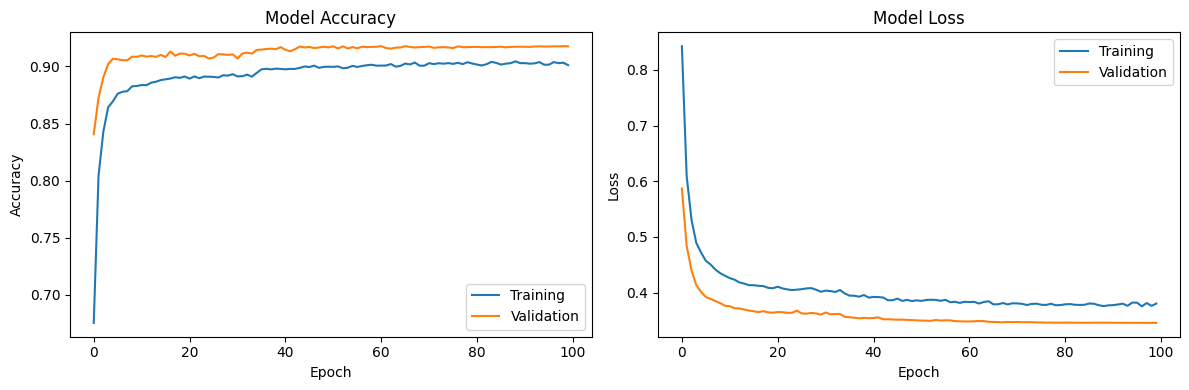

In [57]:
# VISUALIZE TRAINING AND VALIDATION PERFORMANCE
# Plot accuracy and loss across epochs to assess learning behavior
# and identify potential overfitting or underfitting.

# Import Matplotlib for plotting training history.
import matplotlib.pyplot as plt

# Create two side-by-side plots: accuracy and loss.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# SECTION 1: PLOT TRAINING AND VALIDATION ACCURACY
# Compare accuracy across epochs to observe model performance.
axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# SECTION 2: PLOT TRAINING AND VALIDATION LOSS
# Compare loss curves to assess convergence and generalization.
axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

# Adjust spacing so titles and labels do not overlap.
plt.tight_layout()

# Display both plots.
plt.show()

In [58]:
# SAVE THE TRAINED MODEL AND FINAL RESULTS
# Save the deep learning model, preprocessing objects, label encoder,
# and final test evaluation metrics for future use.

# Import libraries for directory management, JSON files, model serialization,
# data handling, and evaluation metrics.
import os
import json
import joblib
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Create directories for saved models and evaluation results.
os.makedirs("outputs/models", exist_ok=True)
os.makedirs("outputs/results", exist_ok=True)

# SECTION 1: SAVE THE TRAINED MODEL
# Save the trained neural network in Keras format.
model.save("outputs/models/player_engagement_mlp.keras")

# Save the fitted preprocessing pipeline for future predictions.
joblib.dump(preprocessor, "outputs/models/preprocessor.joblib")

# Save the label encoder to convert predicted indices into class labels.
joblib.dump(label_encoder, "outputs/models/label_encoder.joblib")

# SECTION 2: CALCULATE FINAL TEST METRICS
# Calculate accuracy and macro F1-score using held-out test predictions.
final_metrics = {
    "test_accuracy": float(
        accuracy_score(y_test, test_predictions)
    ),
    "test_macro_f1": float(
        f1_score(y_test, test_predictions, average="macro")
    )
}

# SECTION 3: SAVE METRICS TO JSON
# Export the evaluation metrics so they can be reused in reports.
with open("outputs/results/final_metrics.json", "w") as f:
    json.dump(final_metrics, f, indent=2)

# SECTION 4: CONFIRM THE SAVED OUTPUTS
# Display a confirmation message and the final evaluation metrics.
print("Final model and metrics saved successfully.")
print(final_metrics)

Final model and metrics saved successfully.
{'test_accuracy': 0.9207459207459208, 'test_macro_f1': 0.9163292852114747}
